In [1]:
import numpy as np
import os
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import h5py

import json

from synch_emission_functions import f_p_0, f_e_0, mp, me, c, ep_ratio, synch_kernel, crit_freq, ekin

In [2]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"
# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [3]:
pp_arr = np.logspace(0., 5, 200)
print(
    f"Minimum & maximum of normalised momentum (protons): {(pp_arr.min() * mp * c**2).to(u.GeV):.5e}, {(pp_arr.max() * mp * c**2).to(u.GeV):.5e}"
)

pe_arr = np.logspace(2, 7, 200)
print(
    f"Minimum & maximum of normalised momentum (electrons): {(pe_arr.min() * me * c**2).to(u.GeV):.5f}, {(pe_arr.max() * me * c**2).to(u.GeV):.5e}"
)

Kep, pp0, pe0 = (
    ep_ratio()
)  # get the normalisation for the electron spectrum based on the proton spectrum at 10 GeV, and the corresponding momenta

Minimum & maximum of normalised momentum (protons): 9.38272e-01 GeV, 9.38272e+04 GeV
Minimum & maximum of normalised momentum (electrons): 0.05110 GeV, 5.10999e+03 GeV
ep ratio parameters: 0.01, 10.658, 19569.512


In [4]:
alpha_inj_p = 4.2
alpha_inj_e = 4.2

dens_val = 1e-25 * (u.g / u.cm**3)
r_pos = 5 * u.pc
vel_val = 100 * u.km/u.s

alpha_inj_vals = [4, 4.2, 4.4, 4.6, 4.8]

mag_vals = [0.1, 1, 10] * u.uG
synch_freqs = np.linspace(0.5, 20, 20) * u.GHz

In [5]:
sim_name = "ISM-v40-MDiff"

ncresynch_ratios = np.zeros((len(alpha_inj_vals), len(mag_vals), len(synch_freqs))) * (u.GeV**-1)

for ialpha, alpha_inj_val in enumerate(alpha_inj_vals):
    for imag, mag_val in enumerate(mag_vals):
        sim_dir = bowshock_config[sim_name]["sim_dir"]

        fp0 = f_p_0(
            alpha_inj_val,
            pp_arr,
            dens_val,
            vel_val,
            pmax=bowshock_config[sim_name]["pmax_prot"],
            vstar=bowshock_config[sim_name]["vstar"] * (u.km/u.s)
        )
        ncr_p = np.trapz(
            4 * np.pi * pp_arr**2 * fp0,
            x=pp_arr,
        )
        ecr_p = np.trapz(
            4 * np.pi * pp_arr**2 * ekin(pp_arr) * mp * c**2 * fp0,
            x=pp_arr,
        ) / ncr_p

        fe0 = f_e_0(
            alpha_inj_val,
            pe_arr,
            dens_val,
            mag_val,
            Tstar=1e4 * u.K,  # assumed based on stellar track from Ekstrom+2012
            vel=vel_val,
            pmax=bowshock_config[sim_name]["pmax_electr"],
            vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
            r_pos=r_pos,
        )

        f_e = Kep * f_p_0(
            alpha_inj_val,
            pp0,
            dens_val,
            vel_val,
            pmax=bowshock_config[sim_name]["pmax_prot"],
            vstar=bowshock_config[sim_name]["vstar"] * (u.km/u.s)
        ) / f_e_0(
            alpha_inj_val,
            pe0,
            dens_val,
            mag_val,
            Tstar=1e4 * u.K,  # assumed based on stellar track from Ekstrom+2012
            vel=vel_val,
            pmax=bowshock_config[sim_name]["pmax_electr"],
            vstar=bowshock_config[sim_name]["vstar"] * (u.km / u.s),
            r_pos=r_pos,
        ) * fe0

        ne = np.trapz(
            4
                * np.pi
                * pe_arr ** 2
                * f_e,
                x=pe_arr,
                axis=0,
            )

        nu_crit = crit_freq(
            Blos=mag_val,
            pele=pe_arr,
        )

        for isynch, synch_freq in enumerate(synch_freqs):
            synch_ker = synch_kernel((synch_freq / nu_crit).value)

            ncre_synch = np.trapz(
                4
                * np.pi
                * pe_arr ** 2
                * f_e
                * synch_ker,
                x=pe_arr,
                axis=0,
            ) / ne

            ncresynch_ratios[ialpha, imag, isynch] = (ncre_synch / ecr_p).to(u.GeV**-1)

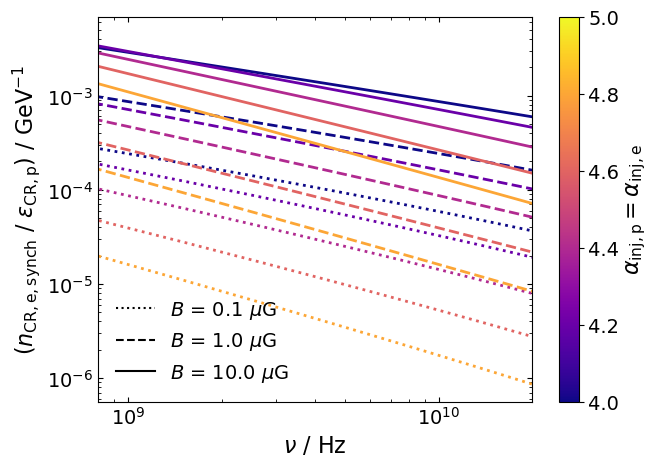

In [6]:
fig, ax = plt.subplots(figsize=(7,5))
alpha_inj_cmap = cm.plasma
alpha_inj_norm = mcolors.Normalize(vmin=4, vmax=5)

mag_lss = [':', '--', '-']

for ialpha_inj, alpha_inj_val in enumerate(alpha_inj_vals):
    for imag, mag_val in enumerate(mag_vals):
        ax.loglog(
            synch_freqs.to_value(u.Hz),
            ncresynch_ratios[ialpha_inj, imag, :].to_value(u.GeV**-1),
            color=alpha_inj_cmap(alpha_inj_norm(alpha_inj_val)),
            ls=mag_lss[imag],
            lw=2.0
        )

ax.set_xlabel(r"$\nu$ / Hz", fontsize=16)
ax.set_ylabel(r"($n_\mathrm{CR, e, synch}$ / $\epsilon_\mathrm{CR, p}$) / GeV$^{-1}$", fontsize=16)

sc = cm.ScalarMappable(cmap=alpha_inj_cmap, norm=alpha_inj_norm)
cbar = fig.colorbar(sc, ax=ax)
cbar.ax.set_ylabel(r"$\alpha_\mathrm{inj, p} = \alpha_\mathrm{inj, e}$", fontsize=16)
cbar.ax.tick_params(axis='both', labelsize=14)

ax.set_xlim(xmin=8e8, xmax=2e10)
# ax.set_ylim(ymin=1e-7, ymax=1e-2)

ax.tick_params(axis='both', which='major', labelsize=14, top=True, right=True, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=14, top=True, right=True, direction='in')

ax.legend(
    handles = [
        mlines.Line2D([], [], label=rf'$B$ = {mag_vals[imag].to_value(u.uG):.1f} $\mu$G', color='k', ls=mag_lss[imag]) for imag in range(len(mag_vals))
    ],
    frameon=False,
    framealpha=0.0,
    fontsize=14
)

fig.savefig(f"{fig_dir}/ncre_synch_ratio.pdf", dpi=200, bbox_inches='tight')